In [ ]:
# Install required packages
!pip install -q torch_geometric
!pip install -q pynndescent
!pip install -q scanpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 48.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 73.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.1/169.1 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.2/58.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.1/254.1 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 86.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.7/53.7 kB 4.9 MB/s eta 0:00:00


In [ ]:
# Import modules
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import anndata as ad
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
import torch_geometric
from torch_geometric.nn import GATConv
import pynndescent
from scipy import sparse as sp
from tqdm import tqdm

In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Alignment
Pre-training of the projection matrix of sc data onto voxels.

# Load data

In [ ]:
# Load MERFISH AnnData
adata_st = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_spatial_train.h5ad')
adata_st

AnnData object with n_obs × n_vars = 10000 × 155
    obs: 'Cell_ID', 'Animal_ID', 'Animal_sex', 'Behavior', 'Bregma', 'Centroid_X', 'Centroid_Y', 'Cell_class', 'Neuron_cluster_ID', 'batch'
    var: 'mean', 'std'
    uns: 'Cell_class_colors', 'log1p'
    obsm: 'spatial', 'spatial3d'

In [ ]:
# Load sc data
adata_sc = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_scRNA_train.h5ad')
adata_sc

AnnData object with n_obs × n_vars = 28390 × 155
    obs: 'Sex', 'Replicate_number', 'Cell_class', 'Non-neuronal_cluster_ID', 'Neuronal_cluster_ID'
    var: 'mean', 'std'
    uns: 'log1p'

# Dataset and DataLoader
The Dataset classes are modified to handle the full datasets for training. In particular, the spatial collate class returns the whole neoghbourhood graph computed with pynndescent.

In [ ]:
def get_knn(location, n_neighbors):
    index = pynndescent.NNDescent(location, n_neighbors=n_neighbors)
    neighbor_idx, neighbor_dist = index.neighbor_graph
    return neighbor_idx, neighbor_dist

def knn_to_adj(knn_idx, knn_dist):

    n_samples, n_neighbors = knn_idx.shape

    row = np.repeat(np.arange(n_samples), n_neighbors)
    col = knn_idx.flatten()
    data = np.ones(n_samples * n_neighbors)

    adj_matrix = sp.csr_matrix((data, (row, col)), shape=(n_samples, n_samples))
    return adj_matrix

def location_to_edge(location, n_neighbors):
    idx, dist = get_knn(location, n_neighbors)
    adj = knn_to_adj(idx, dist)
    edge = torch_geometric.utils.from_scipy_sparse_matrix(adj)[0]
    return edge

In [ ]:
class spatialDataset(Dataset):

    def __init__(self, data_fit, location):
        data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit
        assert len(data_fit) == len(location)
        self.data_fit = data_fit
        self.location = location

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
       return self.data_fit[index], self.location[index],

class rnaDataset(Dataset):

    def __init__(self, data_fit):
        self.data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
        return self.data_fit[index]



class spatialCollate():
    def __init__(self, knn=10, device=None):
        self.knn = knn
        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')

    def __call__(self, batch):
        # Unpack batch into data and locations
        data_list, location_list = zip(*batch)

        # Combine and convert data
        data_tensor = torch.as_tensor(np.vstack(data_list), dtype=torch.float32, device=self.device)

        # Combine locations as NumPy (required by get_knn)
        locations = np.vstack(location_list)

        # Compute edge index from spatial graph
        edge_index = location_to_edge(locations, self.knn).to(self.device)

        return data_tensor, edge_index


# Model definition

## Encoders
The encoders match exactly the architecture of the pre-trained ones.

In [ ]:
class EncoderSC(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, dropout=0.0):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_input, d_hidden),
                                   nn.ReLU(),
                                   nn.Dropout(dropout),
                                   nn.Linear(d_hidden, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_latent))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, x):
        z = self.model(x)
        return z

class GATLayer(nn.Module):
    def __init__(self, d_input, num_heads=4, n_layers=1, dropout=0.0, residual=True):
        super().__init__()
        self.residual = residual
        self.num_heads = num_heads
        self.conv_layers = nn.ModuleList()
        self.n_layers = n_layers

        for i in range(self.n_layers):
            self.conv_layers.append(GATConv(d_input, d_input, heads=num_heads, concat=False))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index):
        if self.residual:
            resid = x
        for layer in self.conv_layers:
            x = layer(x, edge_index)
            x = self.dropout(F.leaky_relu(x))
        if self.residual:
            x += resid
        return x

class EncoderST(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, num_heads=1, n_layers=1, dropout=0.0, residual=True):
        super().__init__()

        self.pre_fc = nn.Sequential(nn.Linear(d_input, d_hidden, bias=True),
                                    nn.ReLU(),
                                    nn.Dropout(dropout),
                                    nn.Linear(d_hidden, d_latent, bias=True))
        self.post_fc = nn.Linear(d_latent, d_latent, bias=True)
        self.gat_layer = GATLayer(d_input=d_latent, num_heads=num_heads, n_layers=n_layers, dropout=dropout, residual=residual)

    def forward(self, x, e):
        z = self.pre_fc(x)
        z = self.gat_layer(z, e)
        z = self.post_fc(z)

        return z

## Alignment Head
The Tangram inspired alignment matrix $M$ is implemented as a `torch.nn.Module` object.

It is  initialized to a Normal distribution $\mathcal{N}(0,1)$.

The full single cell dataset $S$ is register as a buffer that moves with the parameter matrix through devices.

The forward method **softmaxes** the matrix and returns the predicted voxels expression matrix $G_{pred}$.

In [ ]:
class AlignmentMatrix(nn.Module):
    def __init__(self, n_cells, n_spots, device=None, full_scrna=None):
        super().__init__()
        device = device or ('cuda' if torch.cuda.is_available() else 'cpu')

        self.n_cells = n_cells
        self.n_spots = n_spots

        # Trainable alignment matrix
        self.M = nn.Parameter(
            torch.randn(n_cells, n_spots, dtype=torch.float32, device=device),
            requires_grad=True
        )

        if full_scrna is not None:
            if isinstance(full_scrna, np.ndarray):
                full_scrna = torch.as_tensor(full_scrna, dtype=torch.float32)
            else:
                full_scrna = full_scrna.to(torch.float32)

            # Now everything is a float32 tensor, move to device and register as buffer
            self.register_buffer('S', full_scrna.to(device))
        else:
            self.register_buffer('S', None)

    def forward(self):
        M_probs = F.softmax(self.M, dim=1)
        # G_pred
        return M_probs, torch.matmul(M_probs.t(), self.S)

## Alignment Loss
The alignment loss coincides with the unconstrained version of Tangram, which includes the following terms:
* A density term that enforces that the learned density distribution is as similar as possible to the expected uniform density.
* A gene/voxel expression term enforcing that the predicted expression for each gene over the voxels is proportional to the expected gene expression over the voxels.
* A voxel/gene expression term: for each voxel, the predicted gene expression
needs to be proportional to the expected gene expression.
* An entropy regularizer to minimize the entropy of the spatial distribution of each cell, to ensure that the spatial probabilities of each cell are peaked over a narrow portion of space.

In [ ]:
class AlignmentMatrixLoss(nn.Module):
    def __init__(self,
                 lambda_g1=1.0,
                 lambda_g2=1.0,
                 lambda_r=1.0,
                 lambda_d=1.0,
                 n_spots=None):

        super().__init__()
        # Coefficients
        self.lambda_g1 = lambda_g1
        self.lambda_g2 = lambda_g2
        self.lambda_r = lambda_r
        self.lambda_d = lambda_d
        # KL Divergence
        self.kl_loss = torch.nn.KLDivLoss(reduction='sum', log_target=False)
        # Density prior
        self.register_buffer('density_prior', torch.ones(n_spots) / n_spots)  # moves with model to device



    def forward(self, M_probs, G_pred, G):

        # Expression terms
        gv_term = self.lambda_g1 * F.cosine_similarity(G_pred, G, dim=0).mean()  # genes over voxels
        vg_term = self.lambda_g2 * F.cosine_similarity(G_pred, G, dim=1).mean()  # voxels over genes
        expression_term = gv_term + vg_term

        # Define entropy(M) regularizer term (sum all entries - return scalar)
        regularizer_term = self.lambda_r * (torch.log(M_probs) * M_probs).sum()

        # Density term
        d_pred = torch.log(M_probs.sum(axis=0) / M_probs.shape[0])  # predicted cell per spot density
        density_term = self.lambda_d * self.kl_loss(d_pred, self.density_prior)

        # Compute final loss
        total_loss = - expression_term - regularizer_term + density_term

        return total_loss, regularizer_term, gv_term, vg_term, density_term



## Full Model

In [ ]:
class AlignmentModel(nn.Module):

    def __init__(self,
                 d_input,
                 d_hidden,
                 d_latent,
                 n_cells,
                 n_spots,
                 dropout=0.1,
                 lambda_g1=1.0,
                 lambda_g2=1.0,
                 lambda_r=1.0,
                 lambda_d=1.0,
                 encode_data=False,
                 full_spatial=None,
                 full_edge_index=None,
                 full_scrna=None,
                ):

        super().__init__()

        # Loss coefficients
        self.lambda_g1 = lambda_g1
        self.lambda_g2 = lambda_g2
        self.lambda_r = lambda_r
        self.lambda_d = lambda_d

        # Bool for encoding in latent space or use intersection genes space
        self.encode_data = encode_data

        # Pass full datasets as attributes (static)
        self.full_spatial = full_spatial
        self.full_edge_index = full_edge_index
        self.full_scrna = full_scrna

        # print("full_scrna device:", full_scrna.device)
        # print("Model device:", next(self.parameters()).device)

        # Encoders and decoders
        if self.encode_data:
            self.ST_encoder = EncoderST(d_input=d_input, d_hidden=d_hidden, d_latent=d_latent,
                                        num_heads=1, n_layers=1, dropout=dropout, residual=True)

            self.SC_encoder = EncoderSC(d_input=d_input, d_hidden=d_hidden, d_latent=d_latent, dropout=dropout)

            # Freeze encoders
            for param in self.ST_encoder.parameters():
                param.requires_grad = False
            for param in self.SC_encoder.parameters():
                param.requires_grad = False

        # Full datasets encoding in init as they are static variables
        if self.encode_data:
                    # Determine working device from full_scrna or fallback to CPU
            if full_scrna is not None:
                device = full_scrna.device
            else:
                device = torch.device("cpu")

            # Move encoder (or whole model) to correct device
            self.SC_encoder = self.SC_encoder.to(device)
            self.ST_encoder = self.ST_encoder.to(device)

            # Encode full data
            with torch.no_grad():
                SC_full_latent = self.SC_encoder(full_scrna)
                ST_full_latent = self.ST_encoder(full_spatial, full_edge_index)

        else:
            # Use full datasets in original feature space
            SC_full_latent = full_scrna
            ST_full_latent = full_spatial

        # Alignment matrix
        print(f"Allocating M: {n_cells} x {n_spots} ({n_cells * n_spots * 4 / 1024**2:.2f} MB)")
        self.AlignmentMatrix = AlignmentMatrix(n_cells=n_cells, n_spots=n_spots, full_scrna=SC_full_latent)
        print('Done')

        # Target spatial dataset
        self.register_buffer('G', ST_full_latent)

        # Loss
        self.alignment_loss = AlignmentMatrixLoss(self.lambda_g1, self.lambda_g2, self.lambda_r, self.lambda_d, n_spots)


    def forward(self):

        # Project scrna data
        # print("Computing M_probs in forward pass")
        M_probs, G_pred = self.AlignmentMatrix()  # shape: [n_cells, n_spots]
        # print('Done')

        # Alignment loss
        alignment_loss, reg_term, al_gv, al_vg, density_term = self.alignment_loss(M_probs, G_pred, self.G)

        return alignment_loss, reg_term, al_gv, al_vg, density_term, M_probs



# Model Training



An early stopping procedure is implemented to stop training based on relative improvements.

The idea is that when the loss reaches a flat region it has converged to a stable point and, if such point corresponds to a good alignment, the pre-alignment is completed.

In [ ]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0, relative=False):
        self.patience = patience
        self.min_delta = min_delta
        self.relative = relative  # use relative improvement or not
        self.best_loss = float('inf')
        self.counter = 0
        self.stop = False

    def __call__(self, val_loss):
        # Compute threshold for "significant" improvement
        if self.relative:
            delta = self.best_loss * self.min_delta
        else:
            delta = self.min_delta

        if val_loss < self.best_loss - delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True


In [ ]:
# Device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Convert arrays just once
SC_fit = adata_sc.X.astype('float32')
ST_fit = adata_st.X.astype('float32')
ST_location = adata_st.obsm['spatial']

# Dataset creation
spatial_dataset = spatialDataset(ST_fit, ST_location)
rna_dataset = rnaDataset(SC_fit)

# Full adataset batch loading

# scRNA-seq DataLoader
loader_sc = DataLoader(rna_dataset, batch_size=len(rna_dataset), shuffle=False)
full_sc = next(iter(loader_sc))
if isinstance(full_sc, np.ndarray):  # if not a tensor already
    full_sc = torch.as_tensor(full_sc, dtype=torch.float32, device=device)
else:
    full_sc = full_sc.to(device)

# Spatial DataLoader
collate_fn = spatialCollate(knn=10, device=device)
loader_st = DataLoader(spatial_dataset, batch_size=len(spatial_dataset), shuffle=False, collate_fn=collate_fn)
full_st, full_edge_index = next(iter(loader_st))  # already on correct device

In [ ]:
# Set seeds
torch.manual_seed(42)
np.random.seed(42)

encode_data = True

lambda_g1=1.0
lambda_g2=1.0
lambda_r=1e-6 # 1e-4
lambda_d=2.0

# Model instance
model = AlignmentModel(
    d_input=adata_sc.shape[1],
    d_hidden=64,
    d_latent=32,
    dropout=0.1,
    n_cells=adata_sc.shape[0],
    n_spots=adata_st.shape[0],
    lambda_g1=lambda_g1,
    lambda_g2=lambda_g2,
    lambda_r=lambda_r,
    lambda_d=lambda_d,
    encode_data=encode_data,
    full_spatial=full_st,
    full_edge_index=full_edge_index,
    full_scrna=full_sc
    )

# Initialize encoders
if encode_data:
    # Pretrained encoders
    model_path = '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/'

    # Load weights into submodules directly
    model.ST_encoder.load_state_dict(torch.load(model_path + 'spatial_encoder_weights.pth'))
    model.SC_encoder.load_state_dict(torch.load(model_path + 'scrna_encoder_weights.pth'))

    # Check no gradient backrpop
    assert all(not p.requires_grad for p in model.ST_encoder.parameters())
    assert all(not p.requires_grad for p in model.SC_encoder.parameters())

    # Set encoders to evalutation (no backprop or gradients)
    model.ST_encoder.eval()
    model.SC_encoder.eval()

# Set optmizier
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Move to device
model.to(device)

Allocating M: 28390 x 10000 (1082.99 MB)
Done


AlignmentModel(
  (ST_encoder): EncoderST(
    (pre_fc): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
    )
    (post_fc): Linear(in_features=32, out_features=32, bias=True)
    (gat_layer): GATLayer(
      (conv_layers): ModuleList(
        (0): GATConv(32, 32, heads=1)
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (SC_encoder): EncoderSC(
    (model): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): ReLU()
      (5): Linear(in_features=64, out_features=32, bias=True)
    )
  )
  (AlignmentMatrix): AlignmentMatrix()
  (alignment_loss): AlignmentMatrixLoss(
    (kl_loss): KLDivLoss()
  )
)

In [ ]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable_params}")

Trainable parameters: 283900000


In [ ]:
for name, param in model.named_parameters():
    print(f"{name}: {tuple(param.shape)}")

ST_encoder.pre_fc.0.weight: (64, 155)
ST_encoder.pre_fc.0.bias: (64,)
ST_encoder.pre_fc.3.weight: (32, 64)
ST_encoder.pre_fc.3.bias: (32,)
ST_encoder.post_fc.weight: (32, 32)
ST_encoder.post_fc.bias: (32,)
ST_encoder.gat_layer.conv_layers.0.att_src: (1, 1, 32)
ST_encoder.gat_layer.conv_layers.0.att_dst: (1, 1, 32)
ST_encoder.gat_layer.conv_layers.0.bias: (32,)
ST_encoder.gat_layer.conv_layers.0.lin.weight: (32, 32)
SC_encoder.model.0.weight: (64, 155)
SC_encoder.model.0.bias: (64,)
SC_encoder.model.3.weight: (64, 64)
SC_encoder.model.3.bias: (64,)
SC_encoder.model.5.weight: (32, 64)
SC_encoder.model.5.bias: (32,)
AlignmentMatrix.M: (28390, 10000)


In [ ]:
# Training parameters
num_epoch = 10000
patience = 50
log_every_n_epochs = 500

# Logs
loss_log = {"total": [], "entropy reg": [], "genes/voxels": [], "voxels/genes": [], "density term": []}

# Progress bar
pbar = tqdm(total=num_epoch, desc="Training", leave=True)

# Loop
for epoch in range(num_epoch):
        model.train()

        early_stopper = EarlyStopping(patience=patience, min_delta=0.05, relative=True)

        optimizer.zero_grad()

        loss, entropy_reg, align_gv, align_vg, density, M = model()

        loss.backward()
        optimizer.step()

        pbar.update()

        loss_log["total"].append(loss.detach())
        loss_log["entropy reg"].append(entropy_reg.detach() / lambda_r)
        loss_log["genes/voxels"].append(align_gv.detach() / lambda_g1)
        loss_log["voxels/genes"].append(align_vg.detach() / lambda_g2)
        loss_log["density term"].append(density.detach() / lambda_d)

        if (epoch + 1) % log_every_n_epochs == 0:
            print(f"Epoch {epoch+1}:")
            for key, value in loss_log.items():
                print(f"{key}: {value[-1]}")

        # Early stopping check
        early_stopper(loss)
        if early_stopper.stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break



Training:   5%|▌         | 500/10000 [02:02<38:34,  4.10it/s]

Epoch 500:


Training:   5%|▌         | 501/10000 [02:02<38:31,  4.11it/s]

total: 0.07917208969593048
entropy reg: -246625.46875
genes/voxels: 0.1650267243385315
voxels/genes: 0.003066095057874918
density term: 0.000319717510137707


Training:  10%|█         | 1000/10000 [04:03<36:30,  4.11it/s]

Epoch 1000:


... (68 outputs left out)

Training:  95%|█████████▌| 9501/10000 [38:31<02:01,  4.09it/s]

total: -0.5590713620185852
entropy reg: -34179.3671875
genes/voxels: 0.42585453391075134
voxels/genes: 0.1715593934059143
density term: 0.0020815583411604166


Training: 100%|██████████| 10000/10000 [40:33<00:00,  4.11it/s]

Epoch 10000:
total: -0.5653082728385925
entropy reg: -30662.26171875
genes/voxels: 0.4267224073410034
voxels/genes: 0.1734512597322464
density term: 0.0021015657112002373


### Plots

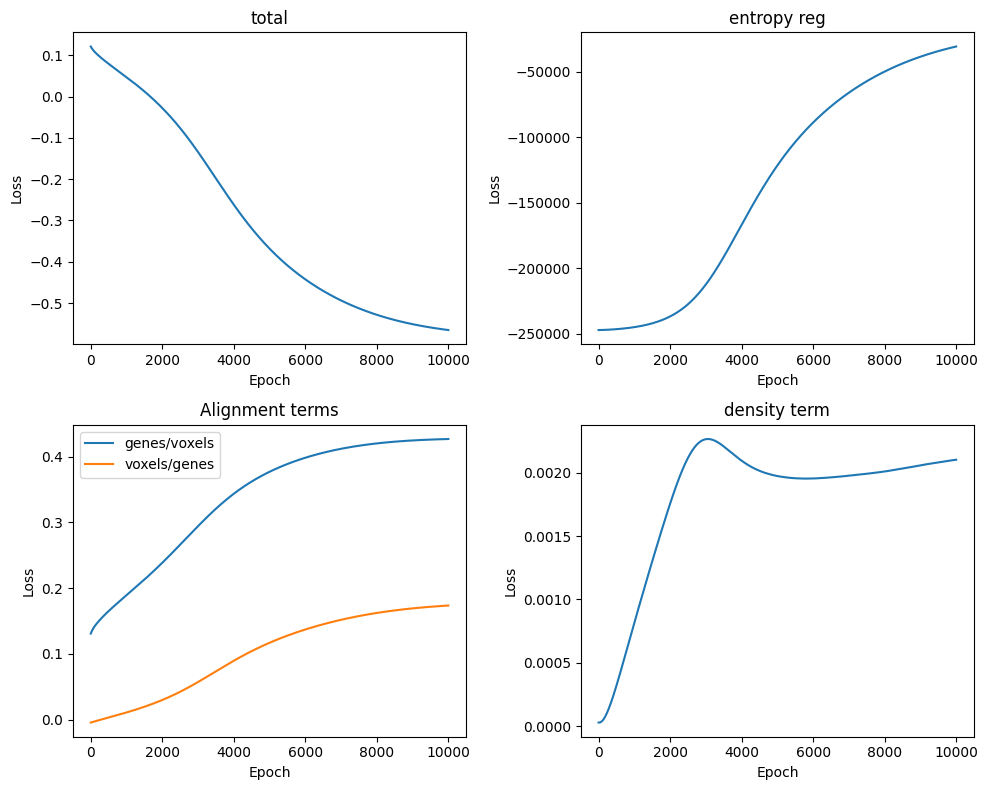

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

plot_keys = list(loss_log.keys())

# First plot: total loss
ax = axs[0, 0]
key = "total"
vals = loss_log[key]
ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals])
ax.set_title(key)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

# Second plot: entropy reg
ax = axs[0, 1]
key = "entropy reg"
vals = loss_log[key]
ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals])
ax.set_title(key)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

# Third plot: alignment terms (grouped)
ax = axs[1, 0]
for key in ["genes/voxels", "voxels/genes"]:
    vals = loss_log[key]
    ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals], label=key)
ax.set_title("Alignment terms")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()

# Fourth plot: density term
ax = axs[1, 1]
key = "density term"
vals = loss_log[key]
ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals])
ax.set_title(key)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

plt.tight_layout()
plt.show()


The alignment reaches a flatter reagion after a huge number of epochs. We can also see that the voxels-over-genes plateaus to a lower similarity wrt to the genes-over-voxels term.

In [ ]:
plt.imshow(M.detach().cpu(), cmap='viridis')
plt.xlabel('Spots')
plt.ylabel('Cells')
plt.title('Alignment Matrix')
plt.colorbar()
plt.show()

# Model no-encoding
A model with no encoding is also trained for comparison.

In this case, the alignment takes place over the original feature space, made of the shared genes, as originally performed in Tangram.

In [ ]:
# Set seeds
torch.manual_seed(42)
np.random.seed(42)

encode_data = False

lambda_g1=1.0
lambda_g2=1.0
lambda_r=0.0
lambda_d=2.0

# Model instance
model_noAE = AlignmentModel(
    d_input=adata_sc.shape[1],
    d_hidden=64,
    d_latent=32,
    dropout=0.1,
    n_cells=adata_sc.shape[0],
    n_spots=adata_st.shape[0],
    lambda_g1=lambda_g1,
    lambda_g2=lambda_g2,
    lambda_r=lambda_r,
    lambda_d=lambda_d,
    encode_data=encode_data,
    full_spatial=full_st,
    full_edge_index=full_edge_index,
    full_scrna=full_sc
    )

# Initialize encoders
if encode_data:
    # Pretrained encoders
    model_path = '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/'

    # Load weights into submodules directly
    model_noAE.ST_encoder.load_state_dict(torch.load(model_path + 'spatial_encoder_weights.pth'))
    model_noAE.SC_encoder.load_state_dict(torch.load(model_path + 'scrna_encoder_weights.pth'))

    # Check no gradient backrpop
    assert all(not p.requires_grad for p in model_noAE.ST_encoder.parameters())
    assert all(not p.requires_grad for p in model_noAE.SC_encoder.parameters())

    # Set encoders to evalutation (no backprop or gradients)
    model_noAE.ST_encoder.eval()
    model_noAE.SC_encoder.eval()

# Set optmizier
optimizer = torch.optim.Adam(model_noAE.parameters(), lr=1e-3)

# Move to device
model_noAE.to(device)

Allocating M: 28390 x 10000 (1082.99 MB)
Done


AlignmentModel(
  (AlignmentMatrix): AlignmentMatrix()
  (alignment_loss): AlignmentMatrixLoss(
    (kl_loss): KLDivLoss()
  )
)

In [ ]:
# Training parameters
num_epoch = 700
patience = 10
log_every_n_epochs = 150

# Logs
loss_log_noAE = {"total": [], "entropy reg": [], "genes/voxels": [], "voxels/genes": [], "density term": []}

# Progress bar
pbar = tqdm(total=num_epoch, desc="Training", leave=True)

# Loop
for epoch in range(num_epoch):
        model_noAE.train()

        early_stopper = EarlyStopping(patience=patience, min_delta=0.05, relative=True)

        optimizer.zero_grad()

        loss, entropy_reg, align_gv, align_vg, density, M = model_noAE()

        loss.backward()
        optimizer.step()

        pbar.update()

        loss_log_noAE["total"].append(loss.detach())
        loss_log_noAE["entropy reg"].append(entropy_reg.detach() / lambda_r)
        loss_log_noAE["genes/voxels"].append(align_gv.detach() / lambda_g1)
        loss_log_noAE["voxels/genes"].append(align_vg.detach() / lambda_g2)
        loss_log_noAE["density term"].append(density.detach() / lambda_d)

        if (epoch + 1) % log_every_n_epochs == 0:
            print(f"Epoch {epoch+1}:")
            for key, value in loss_log_noAE.items():
                print(f"{key}: {value[-1]}")

        # Early stopping check
        early_stopper(loss)
        if early_stopper.stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break




Training: 100%|██████████| 10000/10000 [42:24<00:00,  3.93it/s]

Training:  21%|██▏       | 150/700 [00:40<02:28,  3.71it/s]

Epoch 150:



Training:  22%|██▏       | 151/700 [00:40<02:27,  3.71it/s]

total: -1.52287757396698
entropy reg: nan
genes/voxels: 0.7506623268127441
voxels/genes: 0.7723058462142944
density term: 4.532869206741452e-05



Training:  43%|████▎     | 300/700 [01:20<01:47,  3.71it/s]

Epoch 300:


... (7 outputs left out)

Epoch 600:



Training:  86%|████████▌ | 601/700 [02:41<00:26,  3.70it/s]

total: -1.9810255765914917
entropy reg: nan
genes/voxels: 0.9868738651275635
voxels/genes: 0.9942824244499207
density term: 6.540486356243491e-05



Training: 100%|██████████| 700/700 [03:08<00:00,  3.70it/s]

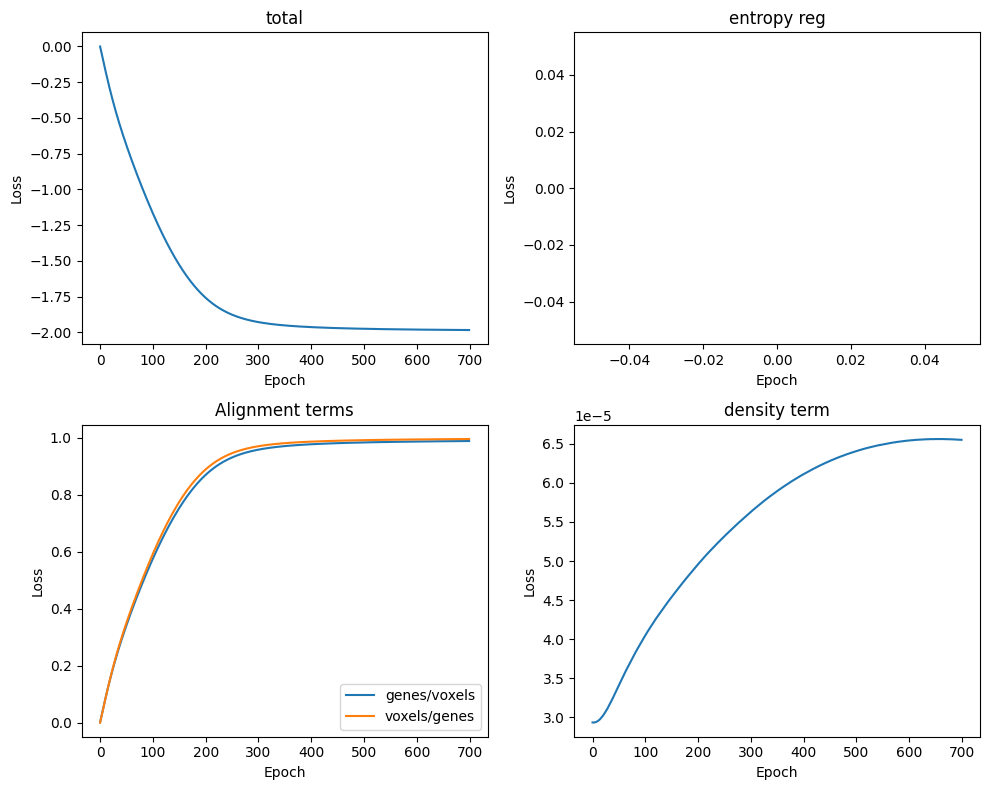

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

plot_keys = list(loss_log_noAE.keys())

# First plot: total loss
ax = axs[0, 0]
key = "total"
vals = loss_log_noAE[key]
ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals])
ax.set_title(key)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

# Second plot: entropy reg
ax = axs[0, 1]
key = "entropy reg"
vals = loss_log_noAE[key]
ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals])
ax.set_title(key)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

# Third plot: alignment terms (grouped)
ax = axs[1, 0]
for key in ["genes/voxels", "voxels/genes"]:
    vals = loss_log_noAE[key]
    ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals], label=key)
ax.set_title("Alignment terms")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()

# Fourth plot: density term
ax = axs[1, 1]
key = "density term"
vals = loss_log_noAE[key]
ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals])
ax.set_title(key)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

plt.tight_layout()
plt.show()


As expected, optimization is significantly faster and more effective: both cosine similarity terms rapidly converge toward the ideal value of 1, indicating that the projected single-cell data can accurately reproduce the spatial expression profiles.

This marked difference in performance suggests that the latent space produced by the current autoencoders may not yet sufficiently capture the underlying structure of the data. This points to the need for more expressive autoencoders or more extensive pre-training to improve the quality of alignment.

Nevertheless, we proceed to evaluate the contrastive learning framework on both types of alignments, with and without the autoencoder-based encoding. In the former case, we will further fine-tune the model using the contrastive loss.

Lastly, we can make the following remarks:
* Loss smoothness is primarely due to the fact that this model does not employ minibatching, thus the gradient signal is deterministically computed on all available points at every epoch
* The KL desnity term increases in both scenarios, meaning that a uniform distribution might not be suitable for the given data.

## Comparison
Head to head plot of alignment terms.

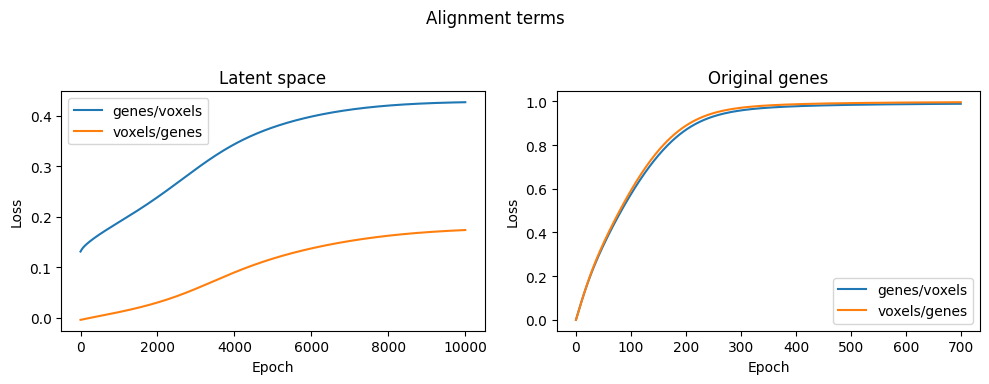

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle("Alignment terms")

# First panel: alignment terms from latent space
ax = axs[0]
for key in ["genes/voxels", "voxels/genes"]:
    vals = loss_log[key]
    ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals], label=key)
ax.set_title("Latent space")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()

# Second panel: alignment terms from original gene space
ax = axs[1]
for key in ["genes/voxels", "voxels/genes"]:
    vals = loss_log_noAE[key]
    ax.plot([v.detach().cpu().item() if torch.is_tensor(v) else v for v in vals], label=key)
ax.set_title("Original genes")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/alignment_terms_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# Importance for CL
The importance matrix is built by computing squared gradients of the alignment loss to estimate parameter importance.

This acts as our EWC weight matrix, as it helps the model remember which weights matter most, so we can prevent them from changing too much during continual learning.

In [ ]:
def compute_importance(model, rna_data, spatial_data, target_param_names=('AlignmentMatrix.M',), device='cpu'):
    model.eval()
    model.to(device)

    importance = {
        name: torch.zeros_like(param, device=device)
        for name, param in model.named_parameters()
        if name in target_param_names
    }

    # Move inputs to device
    rna_data = rna_data.to(device)
    spatial_data = spatial_data.to(device)

    # Forward + backward
    model.zero_grad()  # set gradients to zero
    loss, *_ = model()  # store only total loss
    loss.backward()

    for name, param in model.named_parameters():
        if name in importance and param.grad is not None:
            importance[name] = param.grad.detach().pow(2)  # squared gradient

    # Also store the current (optimal) values for the projection matrix
    opt_params = {
        name: param.detach().clone()
        for name, param in model.named_parameters()
        if name in importance
    }

    return importance, opt_params


In [ ]:
# Compute importance and retrieve optimal parameters
importance, opt_params = compute_importance(model, full_sc, full_st)

# Save for later usage
torch.save({
    'importance': importance,
    'optimal_params': opt_params
}, '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/ewc_alignment.pt')


In [ ]:
# Model wtih no encoding
importance, opt_params = compute_importance(model_noAE, full_sc, full_st)

# Save for later usage
torch.save({
    'importance': importance,
    'optimal_params': opt_params
}, '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/ewc_alignment_noAE.pt')